1.b.i.

In [2]:

import pandas as pd
from sklearn.impute import SimpleImputer

# Load original datasets (read-only)
train = pd.read_csv(
    "../Data/aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)

test = pd.read_csv(
    "../Data/aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)

# Separate features and target
X_train = train.drop(columns=["class"])
y_train = train["class"]

X_test = test.drop(columns=["class"])
y_test = test["class"]

# Check missing values before imputation
print("Missing values before imputation:")
print("Training:", X_train.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())

# Initialize median imputer
imputer = SimpleImputer(
    strategy="median",
    keep_empty_features=True
)

# Fit only on training data
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Apply training medians to test data
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Verify results
print("\nMissing values after imputation:")
print("Training:", X_train_imputed.isna().sum().sum())
print("Test:", X_test_imputed.isna().sum().sum())


Missing values before imputation:
Training: 850015
Test: 228680

Missing values after imputation:
Training: 0
Test: 0


1.b.ii.

In [3]:

import numpy as np
import pandas as pd

# Calculate sample mean for each feature
means = X_train_imputed.mean()

# Calculate sample standard deviation (ddof=1)
stds = X_train_imputed.std(ddof=1)

# Calculate coefficient of variation
cv = stds / means

# Handle division by zero
cv = cv.replace([np.inf, -np.inf], np.nan)

# Create a DataFrame containing the results
cv_results = pd.DataFrame({
    "Feature": X_train_imputed.columns,
    "Mean": means.values,
    "Standard Deviation": stds.values,
    "CV": cv.values
})

# Display all 170 features
print("Number of features:", len(cv_results))

display(cv_results)


Number of features: 170


,Feature,Mean,Standard Deviation,CV
0,aa_000,5.933650e+04,1.454301e+05,2.450938
1,ab_000,1.625000e-01,1.687318e+00,10.383494
2,ac_000,3.362258e+08,7.767625e+08,2.310241
3,ad_000,1.434383e+05,3.504525e+07,244.322816
4,ae_000,6.535000e+00,1.581479e+02,24.200137
...,...,...,...,...
165,ee_007,3.428586e+05,1.718666e+06,5.012754
166,ee_008,1.372212e+05,4.472145e+05,3.259079
167,ee_009,8.295099e+03,4.721249e+04,5.691612
168,ef_000,8.646667e-02,4.268570e+00,49.366659


1.c.iii.

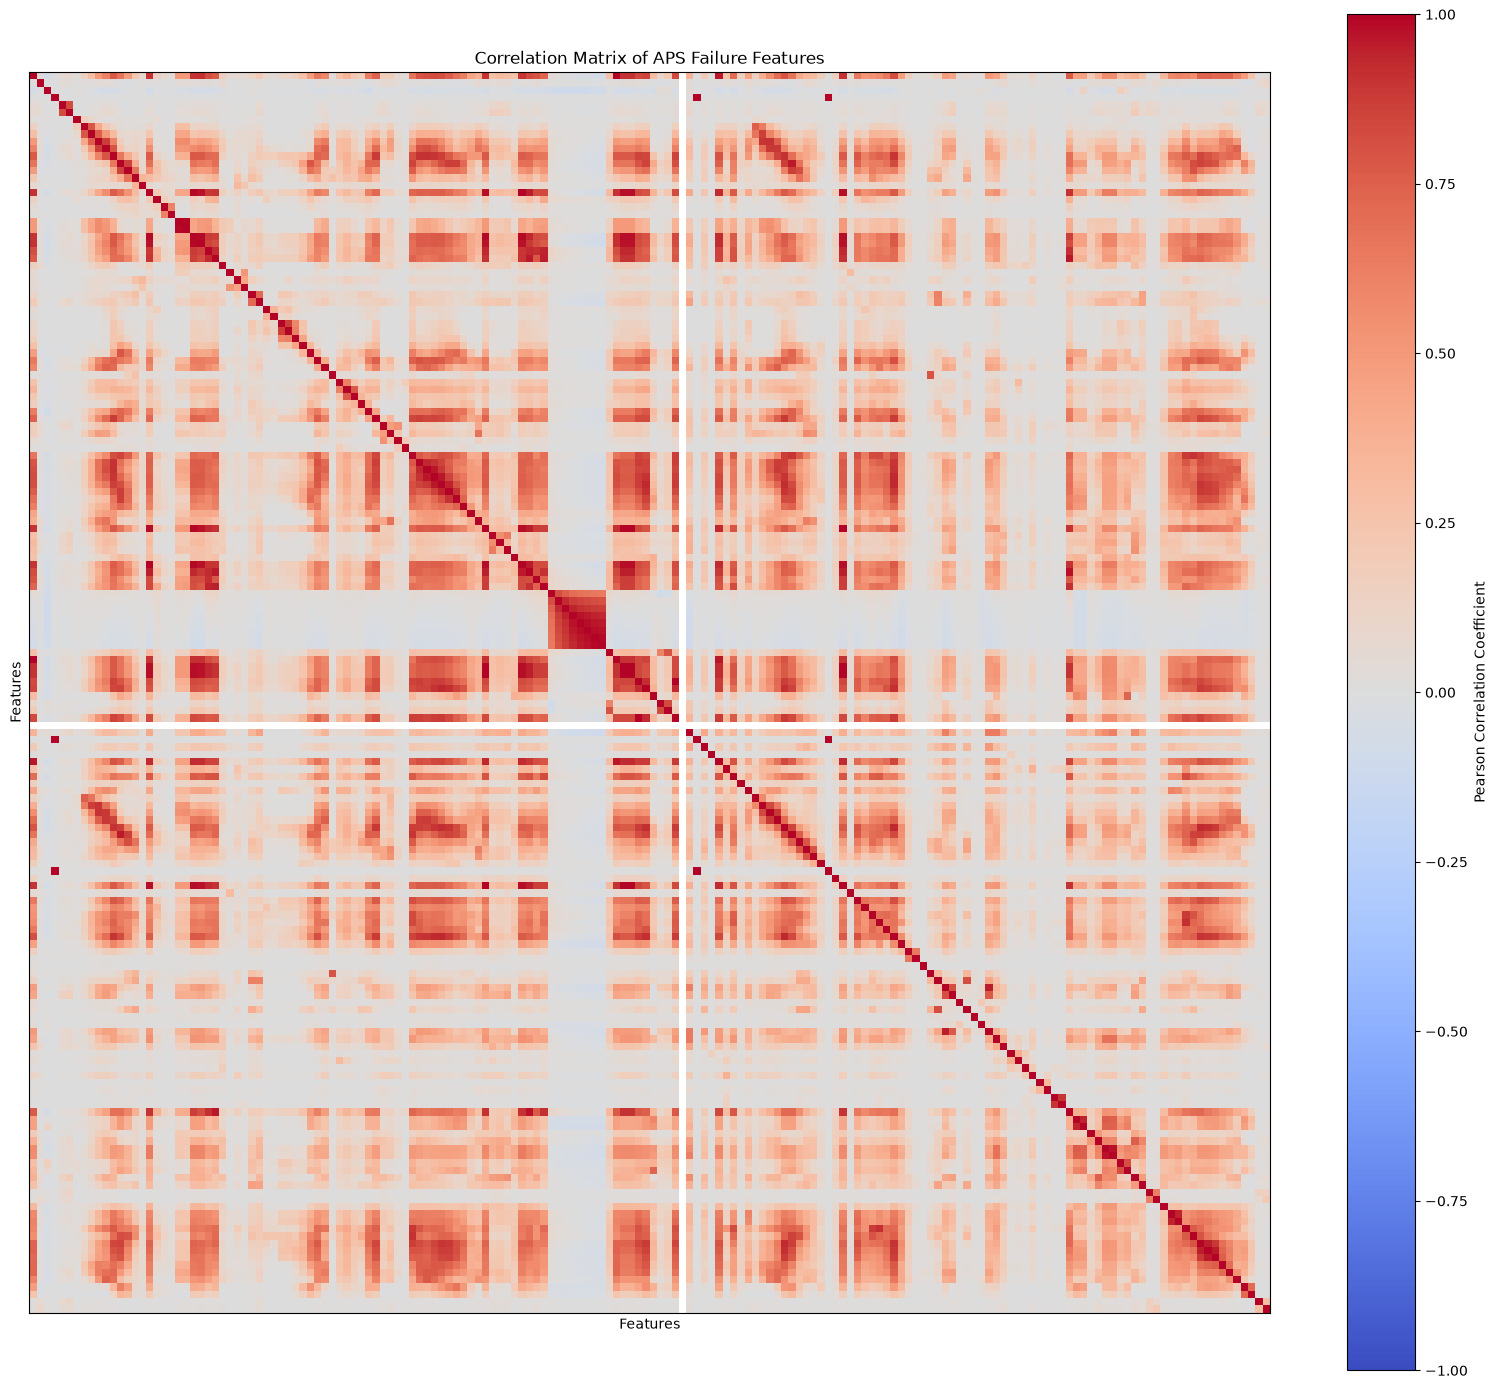

In [ ]:

import matplotlib.pyplot as plt

#Pearson correlation matrix
corr_matrix = X_train_imputed.corr()

plt.figure(figsize=(16, 14))

plt.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    interpolation="nearest"
)

plt.colorbar(label="Pearson Correlation Coefficient")

plt.title("Correlation Matrix of APS Failure Features")
plt.xlabel("Features")
plt.ylabel("Features")

plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()


1.v.iv.

Top 13 features with highest CV:
['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


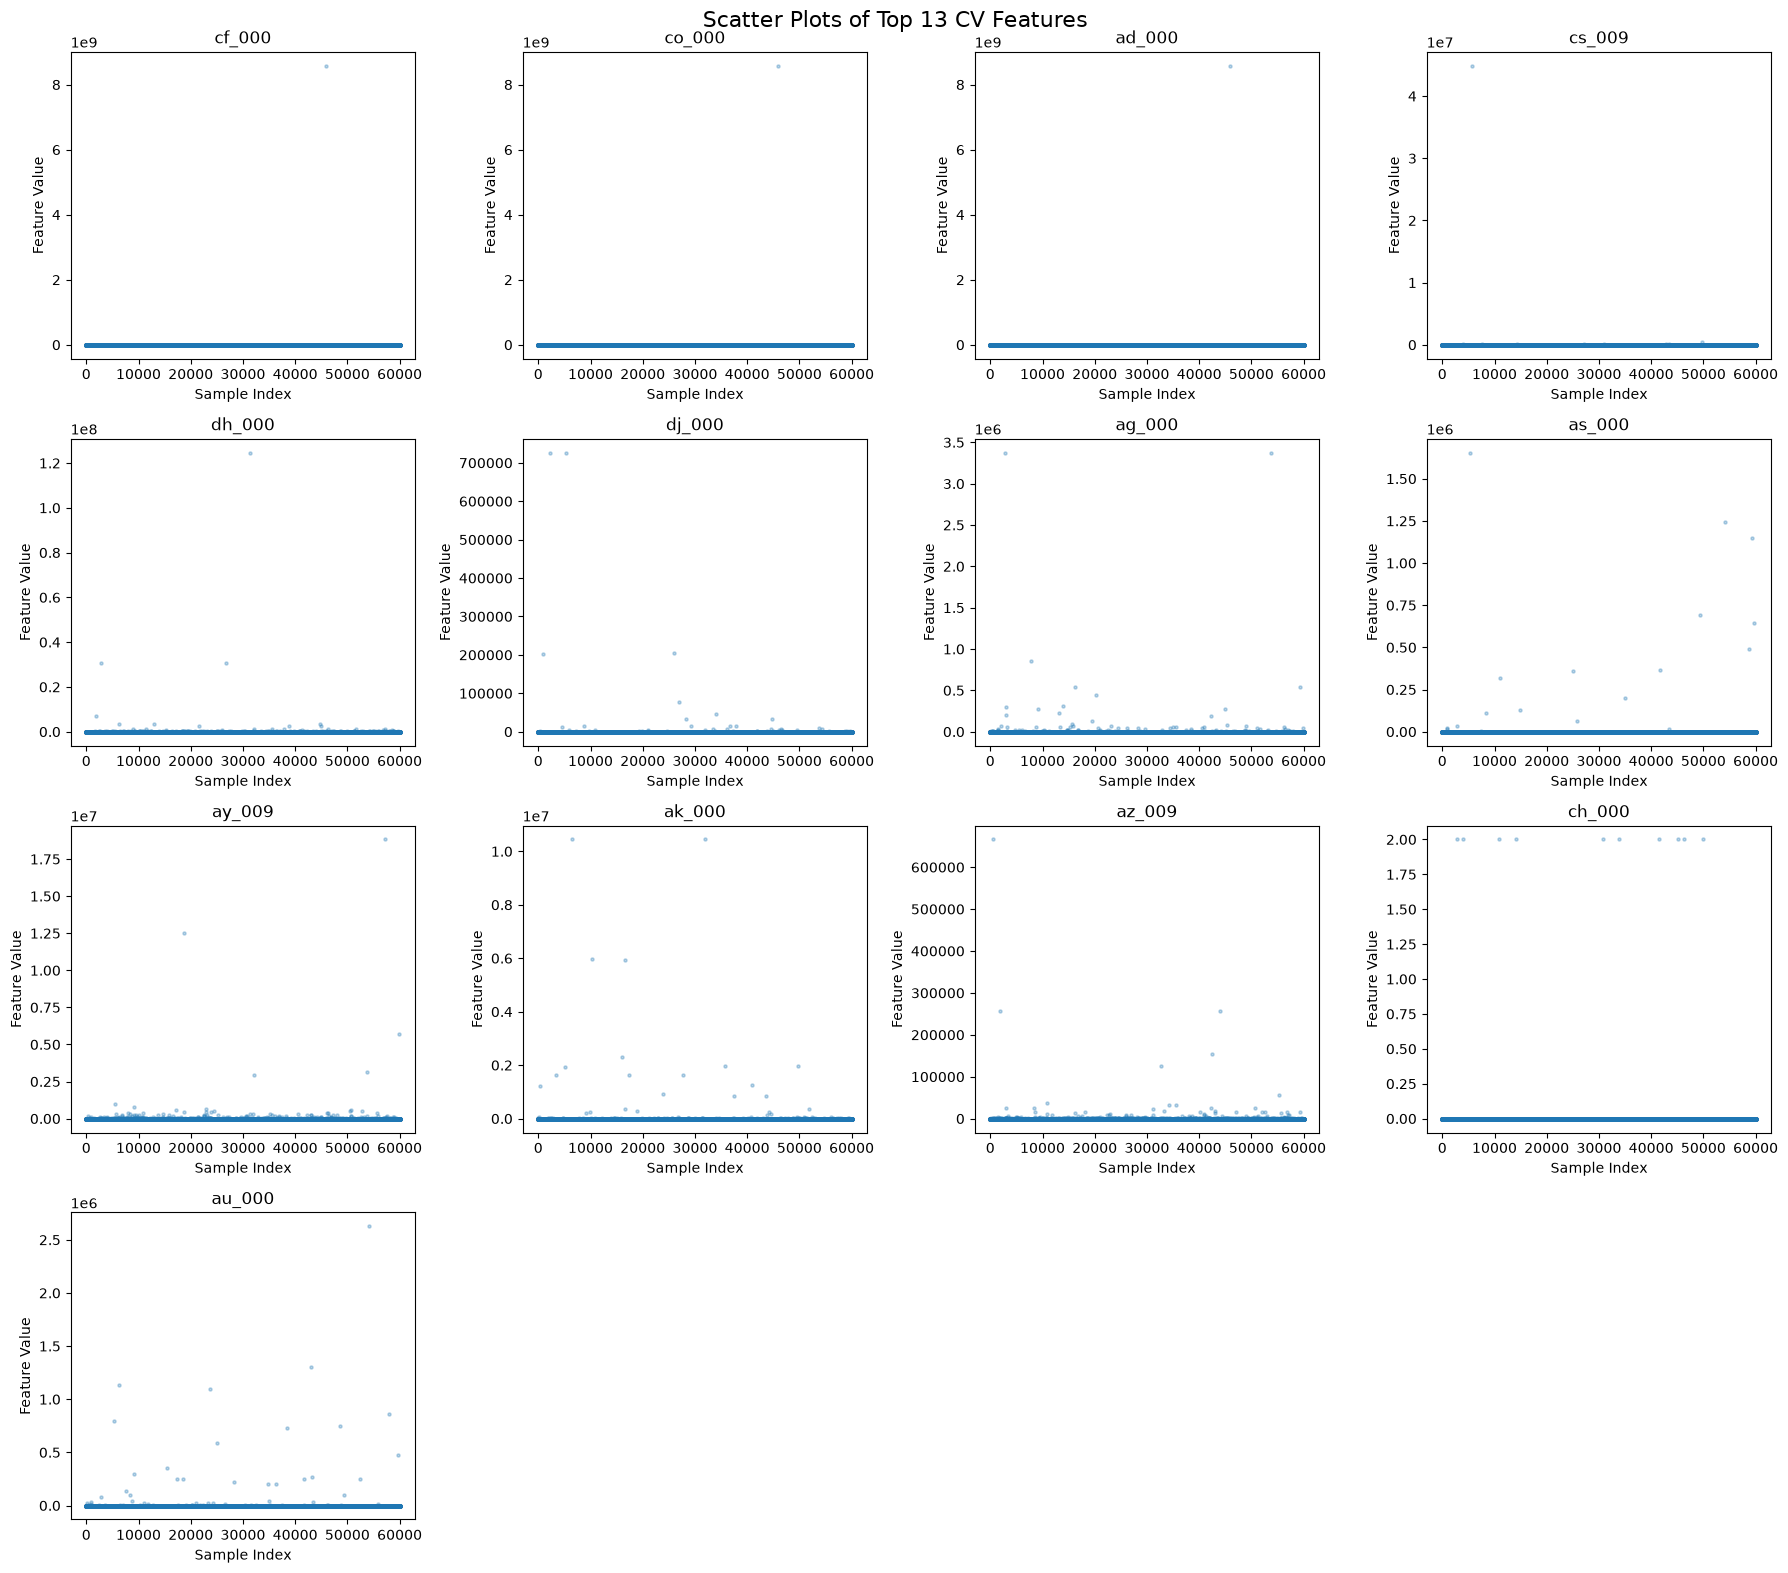

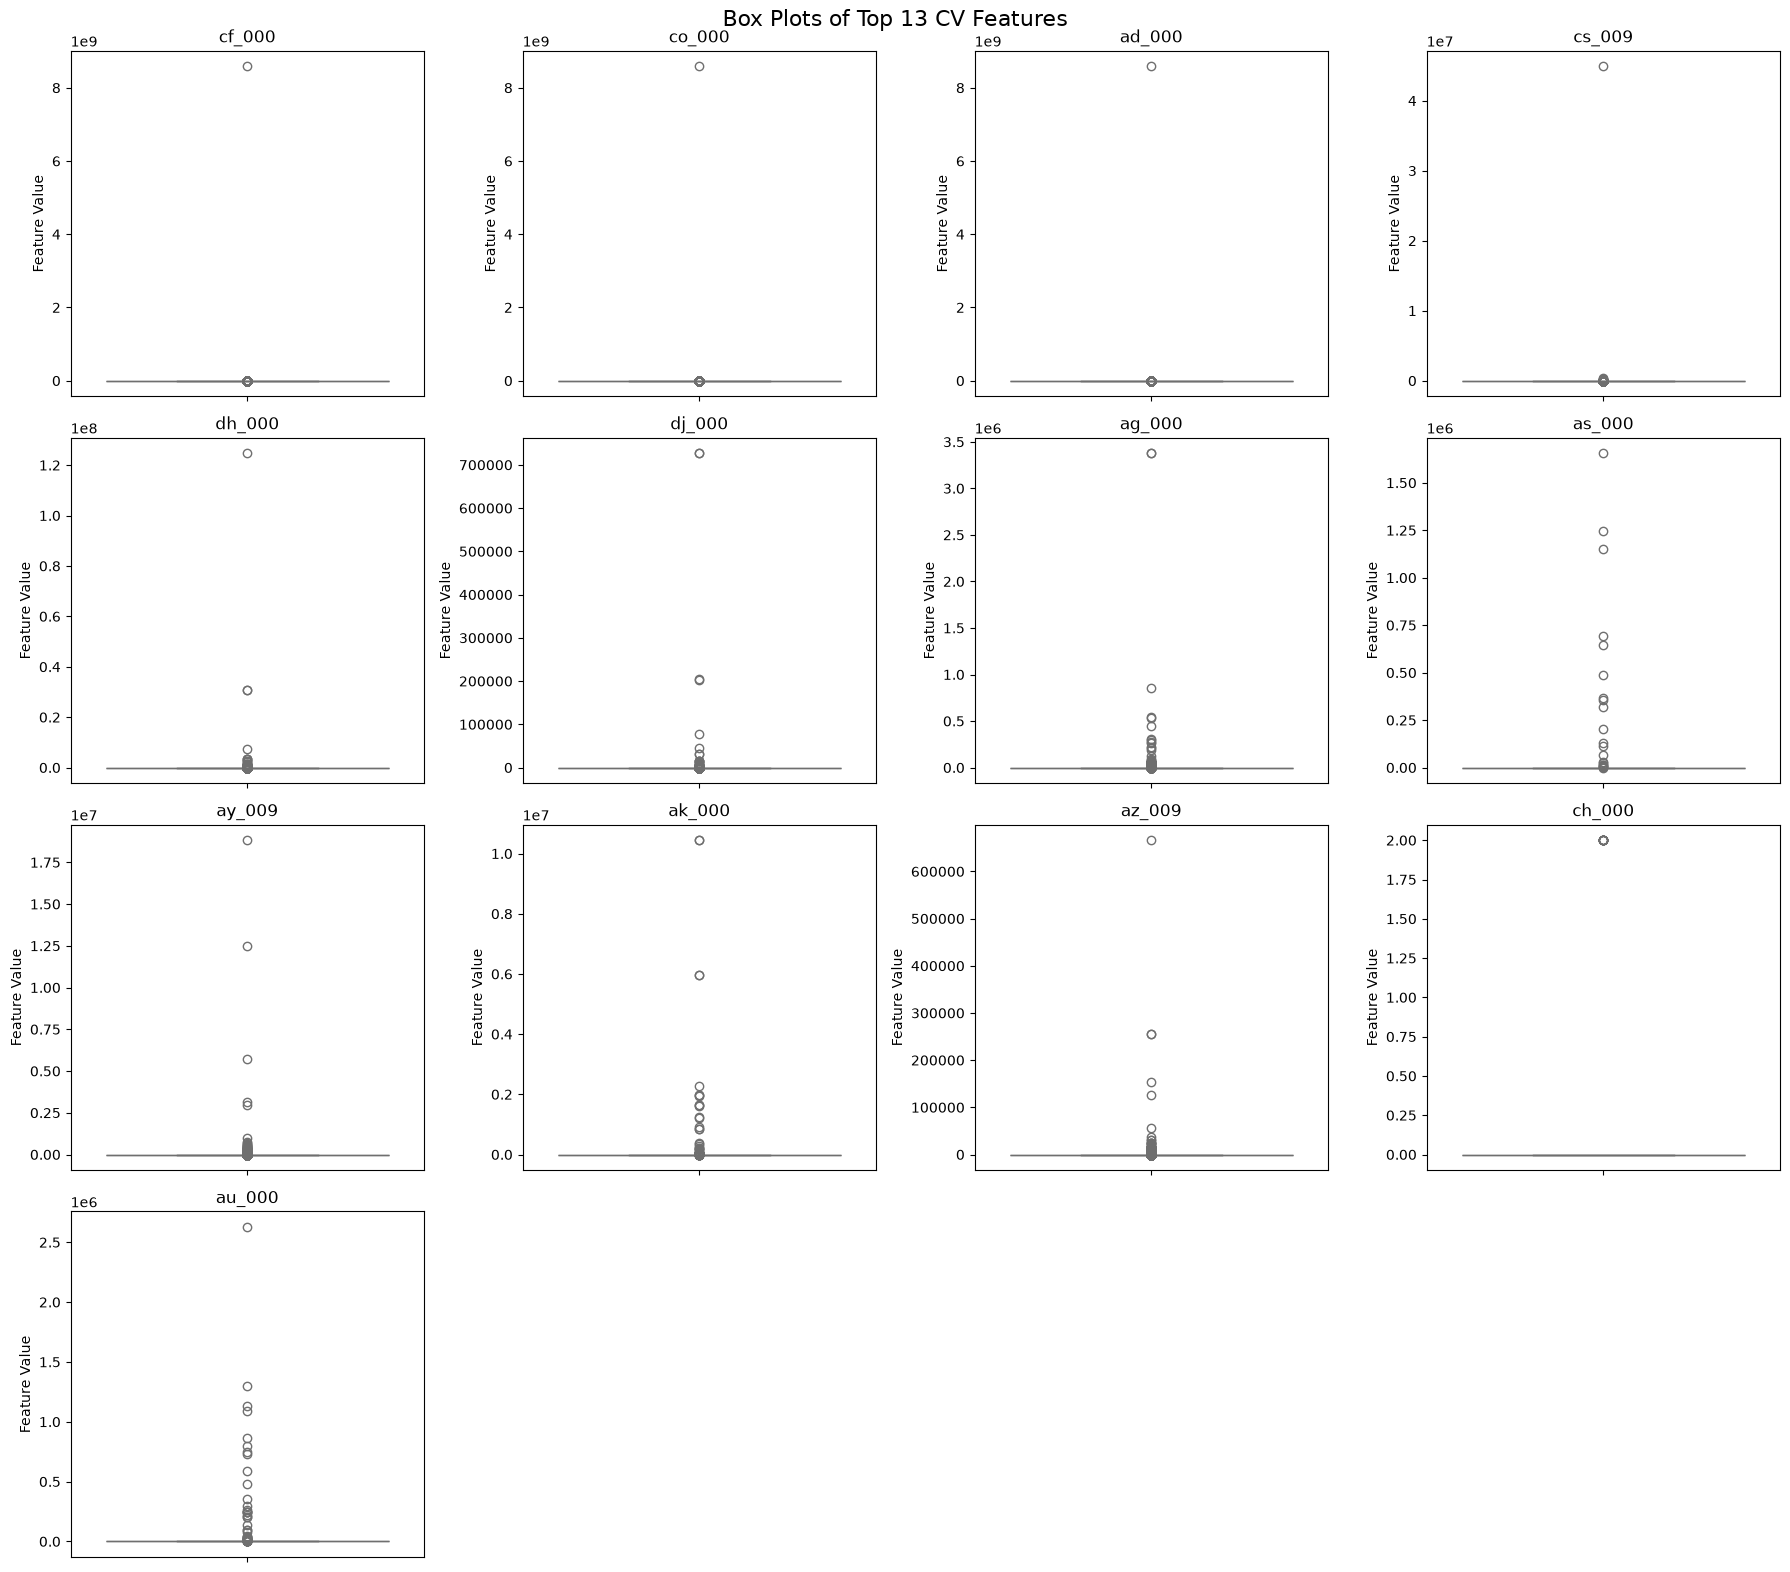

In [5]:
import seaborn as sns

# Number of features to select
n_features = int(np.floor(np.sqrt(170)))

# Select the 13 features with the highest CV
top_features = (
    cv_results
    .dropna(subset=["CV"])
    .sort_values(by="CV", ascending=False)
    .head(n_features)["Feature"]
    .tolist()
)

print(f"Top {n_features} features with highest CV:")
print(top_features)

# Scatter plots
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].scatter(
        X_train_imputed.index,
        X_train_imputed[feature],
        alpha=0.3,
        s=5
    )
    axes[i].set_title(feature)
    axes[i].set_xlabel("Sample Index")
    axes[i].set_ylabel("Feature Value")

# Hide unused subplots
for j in range(len(top_features), len(axes)):
    axes[j].axis("off")

plt.suptitle("Scatter Plots of Top 13 CV Features", fontsize=16)
plt.tight_layout()
plt.show()

# Box plots
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    sns.boxplot(
        y=X_train_imputed[feature],
        ax=axes[i],
        color="skyblue"
    )
    axes[i].set_title(feature)
    axes[i].set_ylabel("Feature Value")

# Hide unused subplots
for j in range(len(top_features), len(axes)):
    axes[j].axis("off")

plt.suptitle("Box Plots of Top 13 CV Features", fontsize=16)
plt.tight_layout()
plt.show()


No, we cannot draw definitive conclusions about the significance of these features based solely on the scatter plots

1.c.

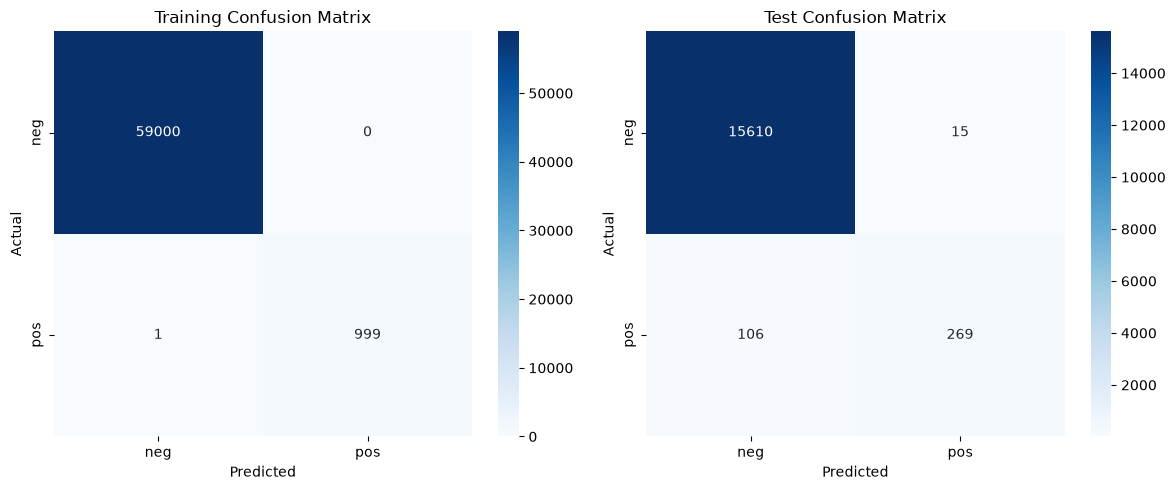

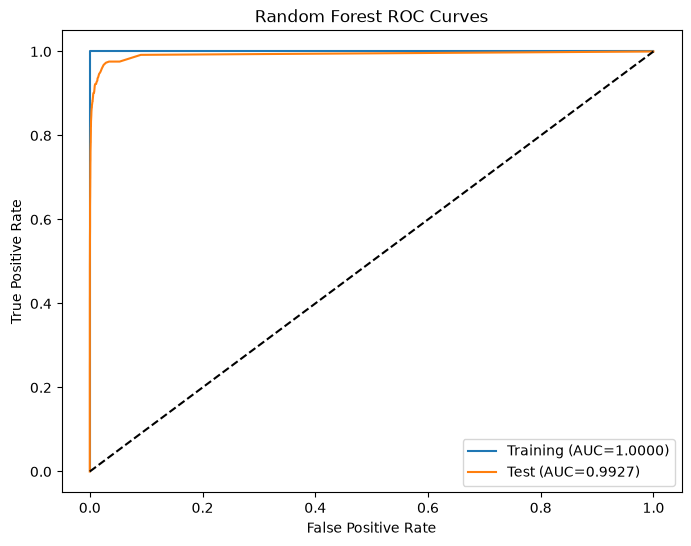

 Dataset      AUC  Misclassification Rate
Training 1.000000                0.000017
    Test 0.992745                0.007563

OOB Error: 0.0062
Test Error: 0.0076
Difference (OOB - Test): -0.0014


In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score

rf = RandomForestClassifier(n_estimators=100, oob_score=True, class_weight=None, random_state=42, n_jobs=-1)
rf.fit(X_train_imputed, y_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plt.figure(figsize=(8, 6))
results = []

for i, (X, y, name) in enumerate([(X_train_imputed, y_train, "Training"), (X_test_imputed, y_test, "Test")]):
    pred = rf.predict(X)
    prob = rf.predict_proba(X)[:, list(rf.classes_).index("pos")]
    cm = confusion_matrix(y, pred, labels=["neg", "pos"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["neg", "pos"], yticklabels=["neg", "pos"], ax=axes[i])
    axes[i].set(title=f"{name} Confusion Matrix", xlabel="Predicted", ylabel="Actual")
    fpr, tpr, _ = roc_curve(y == "pos", prob)
    auc = roc_auc_score(y == "pos", prob)
    plt.figure(2)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")
    results.append([name, auc, 1 - accuracy_score(y, pred)])

fig.tight_layout()
plt.figure(2)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.show()

print(pd.DataFrame(results, columns=["Dataset", "AUC", "Misclassification Rate"]).to_string(index=False))
print(f"\nOOB Error: {1 - rf.oob_score_:.4f}")
print(f"Test Error: {results[1][2]:.4f}")
print(f"Difference (OOB - Test): {1 - rf.oob_score_ - results[1][2]:.4f}")


1.d.

c:\Users\eddy0\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


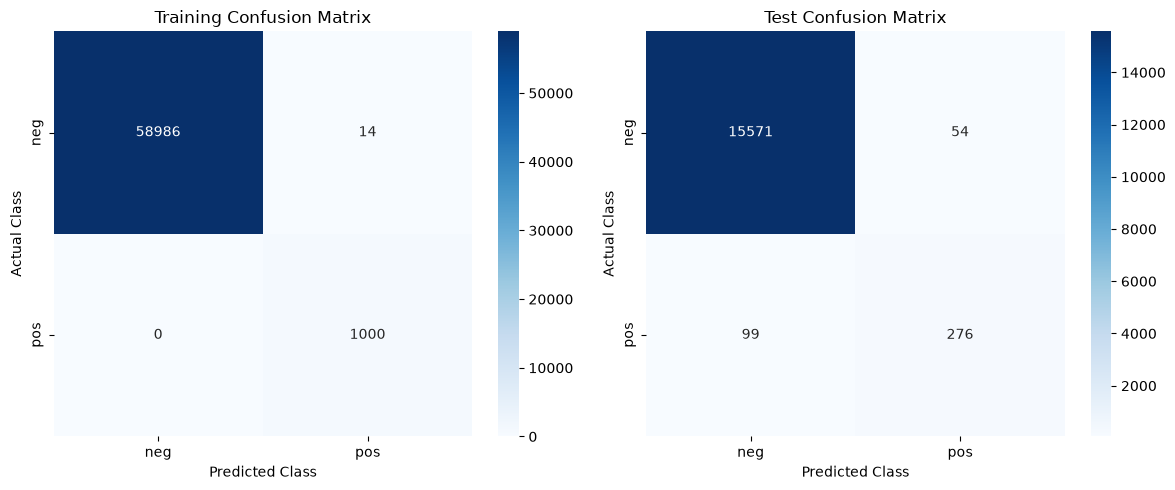

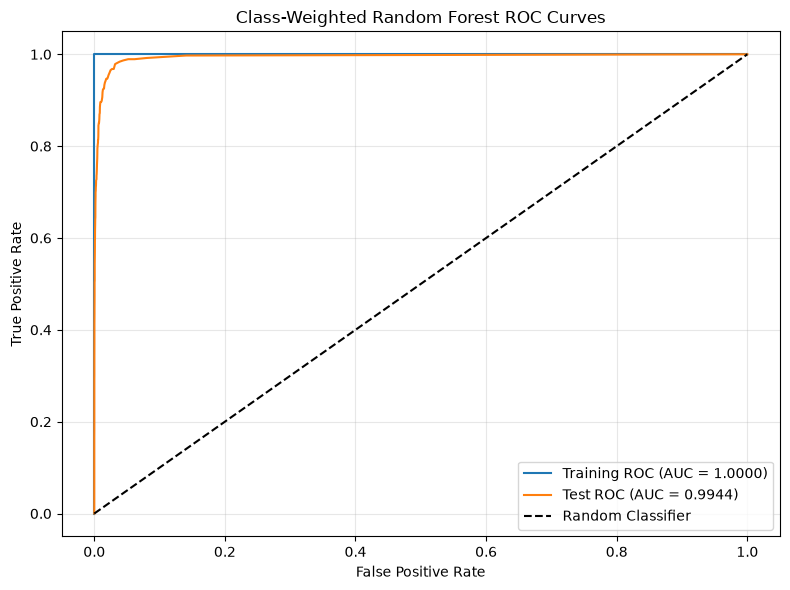


Class-Weighted Random Forest Performance:


,Metric,Training,Test
0,AUC,1.000000,0.994394
1,Misclassification Rate,0.000233,0.009563
2,Accuracy,0.999767,0.990438


OOB Error Estimate: 0.020217
Test Error:         0.009563
Difference:         0.010654


In [8]:

# --------------------------------------------------
# 1. Train Random Forest with class imbalance compensation
# --------------------------------------------------

rf_balanced = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    bootstrap=True,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train_imputed, y_train)

# --------------------------------------------------
# 2. Predictions and probabilities
# --------------------------------------------------

y_train_pred = rf_balanced.predict(X_train_imputed)
y_test_pred = rf_balanced.predict(X_test_imputed)

pos_idx = list(rf_balanced.classes_).index("pos")

y_train_prob = rf_balanced.predict_proba(X_train_imputed)[:, pos_idx]
y_test_prob = rf_balanced.predict_proba(X_test_imputed)[:, pos_idx]

y_train_binary = (y_train == "pos").astype(int)
y_test_binary = (y_test == "pos").astype(int)

# --------------------------------------------------
# 3. Confusion matrices
# --------------------------------------------------

labels = ["neg", "pos"]

cm_train = confusion_matrix(
    y_train, y_train_pred, labels=labels
)

cm_test = confusion_matrix(
    y_test, y_test_pred, labels=labels
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, cm, title in zip(
    axes,
    [cm_train, cm_test],
    ["Training Confusion Matrix", "Test Confusion Matrix"]
):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 4. ROC curves and AUC
# --------------------------------------------------

fpr_train, tpr_train, _ = roc_curve(
    y_train_binary, y_train_prob
)

fpr_test, tpr_test, _ = roc_curve(
    y_test_binary, y_test_prob
)

auc_train = roc_auc_score(
    y_train_binary, y_train_prob
)

auc_test = roc_auc_score(
    y_test_binary, y_test_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_train,
    tpr_train,
    label=f"Training ROC (AUC = {auc_train:.4f})"
)

plt.plot(
    fpr_test,
    tpr_test,
    label=f"Test ROC (AUC = {auc_test:.4f})"
)

plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Class-Weighted Random Forest ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 5. Misclassification rates
# --------------------------------------------------

train_error = 1 - accuracy_score(
    y_train, y_train_pred
)

test_error = 1 - accuracy_score(
    y_test, y_test_pred
)

# --------------------------------------------------
# 6. Out-of-Bag error estimate
# --------------------------------------------------

oob_error = 1 - rf_balanced.oob_score_

# --------------------------------------------------
# 7. Report results
# --------------------------------------------------

results_balanced = pd.DataFrame({
    "Metric": [
        "AUC",
        "Misclassification Rate",
        "Accuracy"
    ],
    "Training": [
        auc_train,
        train_error,
        1 - train_error
    ],
    "Test": [
        auc_test,
        test_error,
        1 - test_error
    ]
})

print("\nClass-Weighted Random Forest Performance:")
display(results_balanced.round(6))

print(f"OOB Error Estimate: {oob_error:.6f}")
print(f"Test Error:         {test_error:.6f}")
print(f"Difference:         {oob_error - test_error:.6f}")


The balanced Random Forest performs slightly worse in overall classification accuracy but better at identifying APS failures. This means that the balanced model is preferable under the dataset's cost function, although the unbalanced model achieves better overall accuracy and a lower test error.

1.e.

In [9]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [14]:

from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score

# Convert labels to binary
y_train_bin = (y_train == "pos").astype(int)
y_test_bin = (y_test == "pos").astype(int)

# Standard XGBoost with L1 regularization
xgb = XGBClassifier(
    booster="gbtree",
    objective="binary:logistic",
    tree_method="hist",
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    reg_lambda=1,
    scale_pos_weight=1,  # No class imbalance compensation
    eval_metric="logloss",
    random_state=42,
    n_jobs=4
)

# 5-fold stratified cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    xgb,
    param_grid={"reg_alpha": [0, 0.01, 0.1, 1, 10]},
    cv=cv,
    scoring="accuracy",
    n_jobs=1,
    verbose=2
)

grid.fit(X_train_imputed, y_train_bin)
model = grid.best_estimator_

print("Best alpha:", grid.best_params_["reg_alpha"])
print(f"5-Fold CV Error: {1 - grid.best_score_:.6f}")


Fitting 5 folds for each of 5 candidates, totalling 25 fits
[CV] END ........................................reg_alpha=0; total time=   0.9s
[CV] END ........................................reg_alpha=0; total time=   0.8s
[CV] END ........................................reg_alpha=0; total time=   0.8s
[CV] END ........................................reg_alpha=0; total time=   0.7s
[CV] END ........................................reg_alpha=0; total time=   0.8s
[CV] END .....................................reg_alpha=0.01; total time=   0.7s
[CV] END .....................................reg_alpha=0.01; total time=   0.7s
[CV] END .....................................reg_alpha=0.01; total time=   0.7s
[CV] END .....................................reg_alpha=0.01; total time=   0.7s
[CV] END .....................................reg_alpha=0.01; total time=   0.7s
[CV] END ......................................reg_alpha=0.1; total time=   0.7s
[CV] END ......................................re

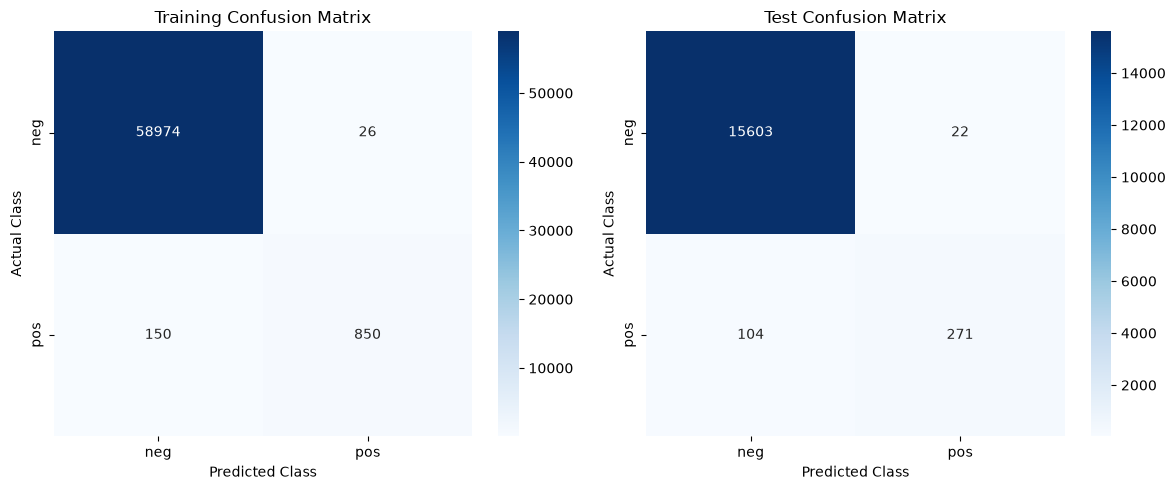

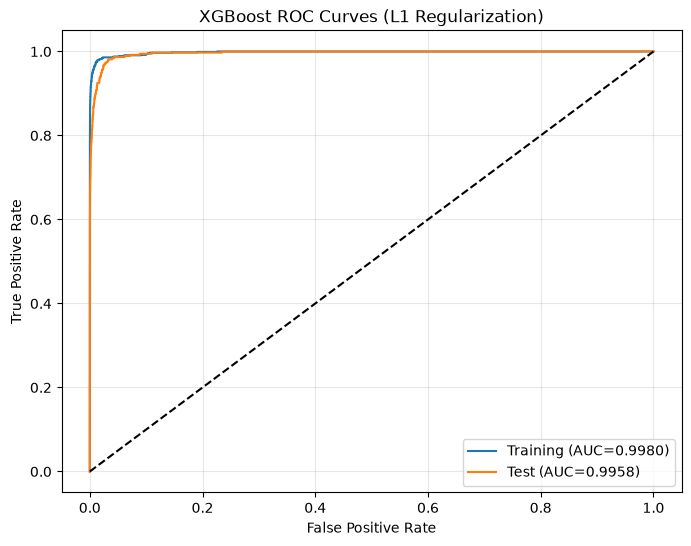

,Dataset,AUC,Misclassification Rate,Accuracy
0,Training,0.997996,0.002933,0.997067
1,Test,0.995812,0.007875,0.992125


Best Alpha:      1
5-Fold CV Error: 0.006367
Test Error:     0.007875
Difference:     -0.001508


In [15]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
results = []

plt.figure(figsize=(8, 6))

for i, (X, y, name) in enumerate([
    (X_train_imputed, y_train_bin, "Training"),
    (X_test_imputed, y_test_bin, "Test")
]):
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]

    cm = confusion_matrix(y, pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["neg", "pos"],
        yticklabels=["neg", "pos"],
        ax=axes[i]
    )
    axes[i].set(
        title=f"{name} Confusion Matrix",
        xlabel="Predicted Class",
        ylabel="Actual Class"
    )

    fpr, tpr, _ = roc_curve(y, prob)
    auc = roc_auc_score(y, prob)
    error = 1 - accuracy_score(y, pred)

    plt.figure(2)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")
    results.append([name, auc, error, 1-error])

fig.tight_layout()

plt.figure(2)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves (L1 Regularization)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

results_df = pd.DataFrame(
    results,
    columns=["Dataset", "AUC", "Misclassification Rate", "Accuracy"]
)

display(results_df.round(6))

cv_error = 1 - grid.best_score_
test_error = results[1][2]

print(f"Best Alpha:      {grid.best_params_['reg_alpha']}")
print(f"5-Fold CV Error: {cv_error:.6f}")
print(f"Test Error:     {test_error:.6f}")
print(f"Difference:     {cv_error-test_error:.6f}")


1.f.

In [16]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [17]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline


# Binary labels
y_train_bin = (y_train == "pos").astype(int)
y_test_bin = (y_test == "pos").astype(int)

# SMOTE + XGBoost pipeline
pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(
        booster="gbtree",
        objective="binary:logistic",
        tree_method="hist",
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        reg_lambda=1,
        scale_pos_weight=1,
        eval_metric="logloss",
        random_state=42,
        n_jobs=4
    ))
])

# 5-fold stratified cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_smote = GridSearchCV(
    pipeline,
    param_grid={"xgb__reg_alpha": [0, 0.01, 0.1, 1, 10]},
    cv=cv,
    scoring="accuracy",
    n_jobs=1,
    verbose=2
)

grid_smote.fit(X_train_imputed, y_train_bin)

model_smote = grid_smote.best_estimator_

print("Best alpha:", grid_smote.best_params_["xgb__reg_alpha"])
print(f"5-Fold CV Error: {1 - grid_smote.best_score_:.6f}")


Fitting 5 folds for each of 5 candidates, totalling 25 fits
[CV] END ...................................xgb__reg_alpha=0; total time=   3.8s
[CV] END ...................................xgb__reg_alpha=0; total time=   1.8s
[CV] END ...................................xgb__reg_alpha=0; total time=   2.0s
[CV] END ...................................xgb__reg_alpha=0; total time=   1.8s
[CV] END ...................................xgb__reg_alpha=0; total time=   1.9s
[CV] END ................................xgb__reg_alpha=0.01; total time=   1.9s
[CV] END ................................xgb__reg_alpha=0.01; total time=   1.9s
[CV] END ................................xgb__reg_alpha=0.01; total time=   2.0s
[CV] END ................................xgb__reg_alpha=0.01; total time=   1.9s
[CV] END ................................xgb__reg_alpha=0.01; total time=   1.8s
[CV] END .................................xgb__reg_alpha=0.1; total time=   1.9s
[CV] END .................................xgb__re